# Parte 3: modelo propuesto (GAM con respuesta binaria + GPD)

Notebook independiente: carga los datos y define solo las funciones que necesita, sin correr las Partes 1 y 2
de `Etapa_final_POT.ipynb`. Necesita en `data/`: `datos_no_imputados.csv` y `pronostico_dia_anterior.csv`.

## Preparación

### Imports y constantes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
from scipy.optimize import minimize
from scipy.stats import chi2, norm, expon, binomtest
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.metrics import roc_auc_score, brier_score_loss
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")

RUTA_DATOS = "../data/datos_no_imputados.csv"
RUTA_FIGURAS = "../figuras/"

VAR = "O3"   # contaminante
U = 63.0     # umbral del modelo
C = 90.0     # norma de 1 h
H = 24       # horizonte del pronóstico (horas)
R = 24       # longitud de racha para el declustering

COORDS = pd.DataFrame(
    [[25.675833, -100.338333], [25.744722, -100.253056], [25.777222, -100.188056],
     [25.790556, -100.078333], [25.762778, -100.369167], [25.800278, -100.584444],
     [25.768333, -100.463611], [25.798611, -100.327222], [25.729722, -100.310000],
     [25.665278, -100.243611], [25.645833, -100.095278], [25.601111, -99.999167],
     [25.675556, -100.458056], [25.665000, -100.412778], [25.616944, -100.273889]],
    index=["CE", "NE", "NE2", "NE3", "NO", "NO2", "NO3", "NTE", "NTE2",
           "SE", "SE2", "SE3", "SO", "SO2", "SUR"], columns=["lat", "lon"])

# Variables meteorológicas del ACP (las mismas de Etapa3_ACP_Logistica)
MET_ACP = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "WDR_sin", "WDR_cos"]

### Funciones de datos

In [2]:
def cargar_datos(ruta):
    d = pd.read_csv(ruta, low_memory=False)

    # En 2024 los datos vienen en columnas con unidades, por ejemplo "O3 (ppb)"
    for col in d.columns:
        if " (" in col:
            nombre = col.split(" (")[0]
            d[nombre] = d[nombre].fillna(d[col])

    d["Fecha y hora"] = pd.to_datetime(d["Fecha y hora"])
    d = d[d["Fecha y hora"] >= "2023-01-01"].copy()

    # Factor de la lluvia indicado por el SIMA
    estaciones_x20 = ["CE", "NE", "NO2", "NO3", "NTE2", "SE", "SO"]
    d.loc[d["Estacion"].isin(estaciones_x20), "RAINF"] *= 20

    # Limpieza: valores negativos o imposibles se vuelven faltantes
    for v in ["O3", "SO2", "PM10", "PM2.5", "NO", "NO2", "NOX", "CO",
              "RAINF", "SR", "WSR", "RH", "PRS"]:
        d.loc[d[v] < 0, v] = np.nan
    d.loc[d["RH"] > 105, "RH"] = np.nan
    d["RH"] = d["RH"].clip(upper=100)
    d.loc[(d["TOUT"] < -10) | (d["TOUT"] > 50), "TOUT"] = np.nan
    d.loc[(d["WDR"] < 0) | (d["WDR"] > 360), "WDR"] = np.nan
    d.loc[d["SR"] > 1.5, "SR"] = np.nan
    d.loc[(d["PRS"] < 650) | (d["PRS"] > 780), "PRS"] = np.nan
    d.loc[d["WSR"] > 150, "WSR"] = np.nan
    d.loc[d["RAINF"] > 100, "RAINF"] = np.nan

    columnas = ["Fecha y hora", "Estacion", "O3", "SO2", "PM10", "PM2.5", "NO2", "NOX", "CO",
                "TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "WDR"]
    return d[columnas]


def etiqueta_periodo(fechas):
    fechas = pd.DatetimeIndex(fechas)
    periodo = np.full(len(fechas), "prueba", dtype=object)
    periodo[fechas < "2026-01-01"] = "validación"
    periodo[fechas < "2025-01-01"] = "entrenamiento"
    return periodo


def agregar_variables(s):
    s = s.copy()
    s["RAINF"] = np.log1p(s["RAINF"])               # la lluvia casi siempre es 0
    angulo = np.deg2rad(s["WDR"])
    s["WDR_sin"] = np.sin(angulo)                   # la dirección es circular
    s["WDR_cos"] = np.cos(angulo)
    s["wind_u"] = -s["WSR"] * np.sin(angulo)        # viento hacia el este
    s["wind_v"] = -s["WSR"] * np.cos(angulo)        # viento hacia el norte
    hora = s.index.hour
    mes = s.index.month
    s["hora_sen1"] = np.sin(2 * np.pi * hora / 24)
    s["hora_cos1"] = np.cos(2 * np.pi * hora / 24)
    s["hora_sen2"] = np.sin(4 * np.pi * hora / 24)
    s["hora_cos2"] = np.cos(4 * np.pi * hora / 24)
    s["mes_sen"] = np.sin(2 * np.pi * (mes - 1) / 12)
    s["mes_cos"] = np.cos(2 * np.pi * (mes - 1) / 12)
    s["periodo"] = etiqueta_periodo(s.index)
    return s


def construir_estaciones(df):
    # Cada estación se pone en una malla horaria completa: una fila = una hora
    horas = pd.date_range(df["Fecha y hora"].min(), df["Fecha y hora"].max(), freq="h")
    crudos = {}
    for nombre in sorted(df["Estacion"].unique()):
        s = df[df["Estacion"] == nombre].drop(columns="Estacion")
        s = s.set_index("Fecha y hora").sort_index()
        s = s[~s.index.duplicated()]
        crudos[nombre] = s.reindex(horas)

    # Marcamos las horas con toda la meteorología medida (el ACP solo usa estas)
    meteo = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF"]
    for s in crudos.values():
        s["met_observada"] = s[meteo + ["WDR"]].notna().all(axis=1)

    # Huecos de meteorología: mediana de las demás estaciones a la misma hora.
    # El ozono NUNCA se rellena.
    relleno = {}
    for nombre in crudos:
        relleno[nombre] = {}
    for v in meteo:
        tabla = pd.DataFrame({n: crudos[n][v] for n in crudos})
        mediana_ciudad = tabla.median(axis=1)
        for n in crudos:
            relleno[n][v] = crudos[n][v].isna().mean()
            crudos[n][v] = crudos[n][v].fillna(mediana_ciudad)

    # La dirección del viento se rellena con la dirección del viento promedio
    seno = pd.DataFrame({n: np.sin(np.deg2rad(crudos[n]["WDR"])) for n in crudos}).mean(axis=1)
    coseno = pd.DataFrame({n: np.cos(np.deg2rad(crudos[n]["WDR"])) for n in crudos}).mean(axis=1)
    direccion_ciudad = (np.degrees(np.arctan2(seno, coseno)) + 360) % 360
    for n in crudos:
        relleno[n]["WDR"] = crudos[n]["WDR"].isna().mean()
        crudos[n]["WDR"] = crudos[n]["WDR"].fillna(direccion_ciudad)

    E = {}
    for n in crudos:
        E[n] = {"datos": agregar_variables(crudos[n]), "relleno": relleno[n]}
    return E

### Carga de datos: una tabla horaria por estación

In [3]:
df = cargar_datos(RUTA_DATOS)
E = construir_estaciones(df)
ESTACIONES = list(E.keys())

filas = []
for st in ESTACIONES:
    s = E[st]["datos"]
    fila = {"estación": st}
    for p in ["entrenamiento", "validación", "prueba"]:
        x = s.loc[s["periodo"] == p, VAR]
        fila[f"{p} > 63"] = int((x > U).sum())
        fila[f"{p} > 90"] = int((x > C).sum())
    filas.append(fila)
pd.DataFrame(filas).set_index("estación")

,entrenamiento > 63,entrenamiento > 90,validación > 63,validación > 90,prueba > 63,prueba > 90
estación,,,,,,
CE,1178,240,781,174,415,99
NE,585,68,506,71,195,32
NE2,286,43,138,9,66,6
NE3,212,11,353,27,91,8
NO,1051,169,752,148,312,57
NO2,1437,269,982,248,523,109
NO3,997,171,402,46,291,38
NTE,818,108,600,93,364,62
NTE2,636,96,437,76,243,47


### Funciones de la GPD, métricas, alertas y pronóstico

In [4]:
# Funciones de la GPD, métricas y alertas (las mismas del notebook Etapa_final_POT) y lectura del pronóstico

def log1p_entre_xi(xi, z):
    # (1/xi) * log(1 + xi*z); cuando xi = 0 el límite es z
    if abs(xi) < 1e-8:
        return z
    return np.log1p(xi * z) / xi


def gpd_nll(parametros, y, Z):
    # -log verosimilitud de la GPD con log(sigma) = Z @ beta y xi constante
    beta = parametros[:-1]
    xi = parametros[-1]
    if xi <= -1:
        return np.inf
    sigma = np.exp(Z @ beta)
    z = y / sigma
    if np.any(1 + xi * z <= 0):        # exceso fuera del soporte
        return np.inf
    return np.sum(np.log(sigma) + (1 + xi) * log1p_entre_xi(xi, z))


def matriz_diseño(datos, covs, media=None, desv=None):
    # Columna de unos + covariables estandarizadas
    if len(covs) == 0:
        return np.ones((len(datos), 1)), None, None
    if media is None:
        media = datos[covs].mean()
        desv = datos[covs].std()
    Zc = ((datos[covs] - media) / desv).to_numpy()
    return np.column_stack([np.ones(len(datos)), Zc]), media, desv


def minimizar(f, x0):
    # Primero Nelder-Mead para acercarse y luego BFGS para afinar
    res1 = minimize(f, x0, method="Nelder-Mead",
                    options={"maxiter": 40000, "xatol": 1e-7, "fatol": 1e-9})
    res2 = minimize(f, res1.x, method="BFGS", options={"gtol": 1e-6})
    if np.isfinite(res2.fun) and res2.fun <= res1.fun:
        return res2
    return res1


def ajustar_gpd(datos, covs, inicio=None):
    # Modelo I: log(sigma) lineal en las covariables, xi constante.
    # datos debe tener la columna "y" con los excesos.
    # inicio: modelo más chico; sus parámetros son el punto de partida (así el
    # modelo grande nunca queda con peor verosimilitud que el chico).
    y = datos["y"].to_numpy()
    Z, media, desv = matriz_diseño(datos, covs)
    f = lambda p: gpd_nll(p, y, Z)

    puntos_iniciales = []
    if inicio is not None:
        anteriores = dict(zip(inicio["nombres"], inicio["params"]))
        x0 = [anteriores.get(n, 0.0) for n in ["intercepto"] + covs] + [anteriores["xi"]]
        puntos_iniciales.append(np.array(x0))
    for xi0 in [0.1, -0.1]:
        x0 = [np.log(y.mean() * (1 - xi0))] + [0.0] * len(covs) + [xi0]
        puntos_iniciales.append(np.array(x0))

    mejor = None
    for x0 in puntos_iniciales:
        if not np.isfinite(f(x0)):
            continue
        res = minimizar(f, x0)
        if mejor is None or res.fun < mejor.fun:
            mejor = res

    return {"params": mejor.x, "nll": mejor.fun, "k": len(mejor.x), "n": len(y),
            "nombres": ["intercepto"] + covs + ["xi"], "covs": covs,
            "media": media, "desv": desv, "Z": Z, "y": y}


def sigma_gpd(m, datos):
    Z, _, _ = matriz_diseño(datos, m["covs"], m["media"], m["desv"])
    return np.exp(Z @ m["params"][:-1])


def prob_mayor_gpd(x, sigma, xi):
    # P(Y > x) para Y ~ GPD(sigma, xi); vale 0 fuera del soporte
    sigma = np.asarray(sigma, dtype=float)
    if abs(xi) < 1e-8:
        return np.exp(-x / sigma)
    t = 1 + xi * x / sigma
    resultado = np.zeros(len(sigma))
    resultado[t > 0] = t[t > 0] ** (-1 / xi)
    return resultado


def hessiana(f, x, eps=1e-4):
    k = len(x)
    Hm = np.zeros((k, k))
    for i in range(k):
        for j in range(i, k):
            ei = np.zeros(k)
            ej = np.zeros(k)
            ei[i] = eps
            ej[j] = eps
            Hm[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * eps ** 2)
            Hm[j, i] = Hm[i, j]
    return Hm


def resumen_gpd(m):
    f = lambda p: gpd_nll(p, m["y"], m["Z"])
    cov = np.linalg.inv(hessiana(f, m["params"]))
    ee = np.sqrt(np.clip(np.diag(cov), 0, None))
    z = m["params"] / ee
    tabla = pd.DataFrame({"coef": m["params"], "ee": ee, "z": z,
                          "p": 2 * (1 - norm.cdf(np.abs(z)))}, index=m["nombres"])
    tabla["exp(coef)"] = np.exp(tabla["coef"])
    tabla.loc["xi", "exp(coef)"] = np.nan
    return tabla


def prueba_rv(chico, grande):
    D = 2 * (chico["nll"] - grande["nll"])
    gl = grande["k"] - chico["k"]
    return D, gl, chi2.sf(D, gl)


def aic(m):
    return 2 * m["nll"] + 2 * m["k"]


def residuales_gpd(m):
    # Si el modelo es correcto, siguen una exponencial(1)
    xi = m["params"][-1]
    sigma = np.exp(m["Z"] @ m["params"][:-1])
    return log1p_entre_xi(xi, m["y"] / sigma)


def metricas(y, p, p_ref=None):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    ok = ~(np.isnan(y) | np.isnan(p))
    resultado = {"n": int(ok.sum()), "eventos": int(y[ok].sum()),
                 "brier": brier_score_loss(y[ok], p[ok]), "auc": roc_auc_score(y[ok], p[ok])}
    if p_ref is not None:
        ref = np.asarray(p_ref, dtype=float)[ok]
        resultado["bss"] = 1 - resultado["brier"] / brier_score_loss(y[ok], ref)
    return resultado


def calibracion(y, p, cortes):
    t = pd.DataFrame({"y": y, "p": p}).dropna()
    grupos = t.groupby(pd.cut(t["p"], cortes, include_lowest=True), observed=True)
    tabla = grupos.agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    return tabla[tabla["n"] >= 30]


def alertas(y, p, tau):
    y = np.asarray(y, dtype=bool)
    alerta = np.asarray(p) >= tau
    return {"tau": tau, "alertas": int(alerta.sum()), "eventos": int(y.sum()),
            "aciertos": (alerta & y).sum() / y.sum(),
            "razón falsas alarmas": (alerta & ~y).sum() / alerta.sum()}


# Temperatura pronosticada un día antes (Open-Meteo); las primeras líneas del CSV son información del punto
import io
lineas = open("../data/pronostico_dia_anterior.csv", encoding="utf-8").read().splitlines()
inicio = 0
while not lineas[inicio].startswith("time"):
    inicio += 1
pron = pd.read_csv(io.StringIO("\n".join(lineas[inicio:])))
pron.columns = ["time", "TOUT", "RH", "SR", "WSR", "WDR", "PRS", "RAINF"]
pron["time"] = pd.to_datetime(pron["time"])
pron = pron.set_index("time")

## Parte 3: modelo propuesto sin supuesto de linealidad (máximo diario, todas las estaciones)

La prueba de la Parte 1B mostró que la logística **no cumple la linealidad en el logit**. En lugar de
defender el modelo lineal, aquí se cambia por uno que **no la supone** y se verifica con un diagnóstico.
Al mismo tiempo se corrigen tres debilidades del modelo horario:

| Debilidad del modelo horario | Cambio en el modelo propuesto |
|---|---|
| Linealidad en el logit no se cumple | **GAM con respuesta binaria**: cada variable continua entra con una curva suave (spline penalizado) |
| Predice la hora exacta de mañana (el pico puede moverse 1–2 h) | Predice el **máximo de mañana**, que es lo que define una alerta |
| Temperaturas muy correlacionadas (0.8) | Se reexpresan como **nivel, cambio y rango** (VIF de 6.4 a 2.6) |
| 15 modelos con pocos eventos cada uno | **Un solo modelo** para todas las estaciones con efecto fijo por estación |
| Excesos horarios dependientes en la GPD | Un máximo por día: los excesos ya están **desagrupados** de forma natural |

Se mantiene la estructura de dos partes: $\zeta = P(\text{máx. de mañana} > 63)$ con el GAM, y el exceso sobre 63 con una GPD cuyo $\log\sigma$ depende (también con spline) de logit $\zeta$.
Entrenamiento 2023–2024, elección con 2025, reporte con 2026.

In [5]:
# =====================================================================
# PARTE 3. Modelo propuesto: máximo diario, todas las estaciones juntas,
# logística aditiva con splines (sin suponer linealidad) + GPD
# =====================================================================

# --- 3.1 Tabla diaria: una fila = (estación, día de hoy); objetivo = máximo de mañana ---
o3_dia = pd.DataFrame({st: E[st]["datos"][VAR].resample("D").max()
                       .where(E[st]["datos"][VAR].resample("D").count() >= 18)
                       for st in ESTACIONES})
ciudad_dia = o3_dia.mean(axis=1)
t_max_pron = pron["TOUT"].resample("D").max()      # temperatura máxima pronosticada (día anterior)
t_min_pron = pron["TOUT"].resample("D").min()

partes = []
for st in ESTACIONES:
    s = E[st]["datos"]
    t = pd.DataFrame(index=o3_dia.index)
    t["estacion"] = st
    t["o3max"] = o3_dia[st]
    t["o3media"] = s[VAR].resample("D").mean()
    t["horas63"] = (s[VAR] > U).resample("D").sum().where(t["o3max"].notna())
    t["horas63_7d"] = t["horas63"].rolling(7, min_periods=4).sum()
    t["o3max_ciudad"] = ciudad_dia
    t["T_max_hoy"] = s["TOUT"].resample("D").max()
    t["SR_max_hoy"] = s["SR"].resample("D").max()
    t["RH_media_hoy"] = s["RH"].resample("D").mean()
    t["WSR_media_hoy"] = s["WSR"].resample("D").mean()
    manana = t.index + pd.Timedelta(days=1)
    t["T_max_pron"] = t_max_pron.reindex(manana).to_numpy()
    t["T_min_pron"] = t_min_pron.reindex(manana).to_numpy()
    t["max_manana"] = o3_dia[st].shift(-1)
    t["mes_sen"] = np.sin(2 * np.pi * (manana.month - 1) / 12)
    t["mes_cos"] = np.cos(2 * np.pi * (manana.month - 1) / 12)
    t["sabado"] = (manana.dayofweek == 5).astype(float)
    t["domingo"] = (manana.dayofweek == 6).astype(float)
    t["fecha"] = manana
    partes.append(t)

DIA = pd.concat(partes, ignore_index=True)
# Las tres temperaturas (máxima de hoy, máxima y mínima pronosticadas) están muy correlacionadas (0.8).
# Para poder separar sus curvas se reexpresan como nivel, cambio y rango (mismo contenido, menos correlación):
DIA["dT_pron"] = DIA["T_max_pron"] - DIA["T_max_hoy"]        # ¿mañana será más caliente que hoy?
DIA["rango_pron"] = DIA["T_max_pron"] - DIA["T_min_pron"]     # oscilación del día (cielo despejado)
CLIMA_D = ["SR_max_hoy", "RH_media_hoy", "WSR_media_hoy", "T_max_pron", "dT_pron", "rango_pron"]
CONT_D = ["o3max", "o3media", "horas63", "horas63_7d", "o3max_ciudad"] + CLIMA_D
CAL_D = ["mes_sen", "mes_cos", "sabado", "domingo"]
DIA = DIA.dropna(subset=CONT_D + ["T_max_hoy", "T_min_pron", "max_manana"]).reset_index(drop=True)
DIA["y63"] = (DIA["max_manana"] > U).astype(float)
DIA["y90"] = (DIA["max_manana"] > C).astype(float)
DIA["periodo"] = etiqueta_periodo(DIA["fecha"])
ESTAC_D = []
for st in ESTACIONES[1:]:                      # efecto fijo por estación (la primera es la referencia)
    DIA["est_" + st] = (DIA["estacion"] == st).astype(float)
    ESTAC_D.append("est_" + st)

ent_d = DIA[DIA["periodo"] == "entrenamiento"]
print("Filas (estación-día):", DIA.groupby("periodo").size().to_dict())
print("Días con máximo > 63:", DIA.groupby("periodo")["y63"].sum().to_dict())
print("Días con máximo > 90:", DIA.groupby("periodo")["y90"].sum().to_dict())

Filas (estación-día): {'entrenamiento': 9716, 'prueba': 3045, 'validación': 4960}
Días con máximo > 63: {'entrenamiento': 3232.0, 'prueba': 1128.0, 'validación': 2129.0}
Días con máximo > 90: {'entrenamiento': 822.0, 'prueba': 344.0, 'validación': 609.0}


In [6]:
# --- 3.2 Logística aditiva: cada variable continua entra con un spline cúbico restringido ---
def spline_restringido(x, nudos):
    # Lineal antes del primer nudo y después del último; k nudos -> k - 2 columnas no lineales
    x = np.asarray(x, dtype=float)
    t = np.asarray(nudos, dtype=float)
    k = len(t)
    pos = lambda z: np.clip(z, 0, None) ** 3
    cols = []
    for j in range(k - 2):
        f = (pos(x - t[j])
             - pos(x - t[k - 2]) * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
             + pos(x - t[k - 1]) * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2]))
        cols.append(f / (t[-1] - t[0]) ** 2)
    return np.column_stack(cols)


NUDOS = {}
SPL = []
for v in CONT_D:
    # 4 nudos en los cuantiles 5, 35, 65 y 95 % del ENTRENAMIENTO (Harrell, 2015)
    nudos = np.unique(np.quantile(ent_d[v], [0.05, 0.35, 0.65, 0.95]))
    if len(nudos) < 4:
        # variables de conteo con muchos ceros: un nudo en 0 y tres en los cuantiles de los valores positivos
        positivos = ent_d.loc[ent_d[v] > 0, v]
        nudos = np.unique(np.r_[0, np.quantile(positivos, [0.1, 0.5, 0.9])])
    NUDOS[v] = nudos
    B = spline_restringido(DIA[v], nudos)
    for j in range(B.shape[1]):
        DIA[f"{v}_s{j + 1}"] = B[:, j]
        SPL.append(f"{v}_s{j + 1}")
ent_d = DIA[DIA["periodo"] == "entrenamiento"]


def logit_diaria(datos, variables, y):
    # Logística con errores robustos agrupados por FECHA (las estaciones del mismo día están correlacionadas)
    media, desv = datos[variables].mean(), datos[variables].std()
    X = sm.add_constant((datos[variables] - media) / desv)
    grupos = pd.factorize(datos["fecha"])[0]
    res = sm.Logit(datos[y], X).fit(disp=0, maxiter=300, cov_type="cluster", cov_kwds={"groups": grupos})
    return {"res": res, "media": media, "desv": desv, "variables": variables}


def predecir_d(m, datos):
    X = sm.add_constant((datos[m["variables"]] - m["media"]) / m["desv"], has_constant="add")
    return m["res"].predict(X).to_numpy()


LINEAL_D = CONT_D + CAL_D + ESTAC_D
ADITIVO_D = CONT_D + SPL + CAL_D + ESTAC_D
m_lin = logit_diaria(ent_d, LINEAL_D, "y63")
m_adi = logit_diaria(ent_d, ADITIVO_D, "y63")

# Prueba de Wald (robusta) de que TODOS los términos no lineales valen 0
w = m_adi["res"].wald_test(" = 0, ".join(SPL) + " = 0", scalar=True)
print(f"Wald no linealidad: {float(w.statistic):.1f} con {len(SPL)} gl, p = {float(w.pvalue):.2g}")
print(f"AIC lineal: {m_lin['res'].aic:.1f} | AIC aditivo: {m_adi['res'].aic:.1f}")

# Wald por variable: ¿cuáles son no lineales?
filas = []
for v in CONT_D:
    cols = [c for c in SPL if c.startswith(v + "_s")]
    wv = m_adi["res"].wald_test(" = 0, ".join(cols) + " = 0", scalar=True)
    filas.append({"variable": v, "Wald": float(wv.statistic), "gl": len(cols), "p": float(wv.pvalue)})
pd.DataFrame(filas).set_index("variable").round(4)

Wald no linealidad: 100.3 con 22 gl, p = 5.8e-12
AIC lineal: 8193.2 | AIC aditivo: 7920.2


,Wald,gl,p
variable,,,
o3max,29.4878,2,0.0000
o3media,6.6060,2,0.0368
horas63,0.4662,2,0.7921
horas63_7d,7.4229,2,0.0244
o3max_ciudad,3.0423,2,0.2185
SR_max_hoy,0.9562,2,0.6200
RH_media_hoy,5.0697,2,0.0793
WSR_media_hoy,13.5271,2,0.0012
T_max_pron,9.9180,2,0.0070


**Lectura.** La no linealidad es real: los términos no lineales son significativos en conjunto (Wald
robusto por día, $p \approx 6 \times 10^{-12}$) y bajan el AIC de 8193 a 7920. Las variables más curvas son el
máximo de ozono de hoy (`o3max`), la velocidad del viento, la temperatura pronosticada y su cambio respecto
a hoy (`dT_pron`).

In [7]:
# --- 3.2b GAM penalizado con respuesta binaria (Wood, 2017) ---
# Cada variable continua entra con un B-spline cúbico de 8 bases y una penalización a la curvatura.
# La penalización (alpha) controla qué tan suave es la curva: se elige con la validación 2025.
# (Los criterios automáticos tipo GCV/UBRE suponen observaciones independientes; aquí las 15
#  estaciones del mismo día están correlacionadas, así que tienden a dejar curvas demasiado onduladas.)
from statsmodels.gam.api import GLMGam, BSplines

LIN_GAM = CAL_D + ESTAC_D                          # partes que entran lineales (calendario y estación)


def ajustar_gam(datos, alpha, cont=CONT_D):
    limites = [{"lower_bound": DIA[v].min(), "upper_bound": DIA[v].max()} for v in cont]
    bases = BSplines(datos[cont].to_numpy(), df=[8] * len(cont), degree=[3] * len(cont),
                     include_intercept=False, knot_kwds=limites)
    X = sm.add_constant(datos[LIN_GAM])
    modelo = GLMGam(datos["y63"], exog=X, smoother=bases, alpha=[alpha] * len(cont),
                    family=sm.families.Binomial())
    res = modelo.fit()
    res.cont = cont                                    # guardamos qué variables usa
    return res


def predecir_gam(res, datos):
    X = sm.add_constant(datos[LIN_GAM], has_constant="add")
    return np.asarray(res.predict(exog=X, exog_smooth=datos[res.cont].to_numpy()))


val_d = DIA[DIA["periodo"] == "validación"]
clima63_d = ent_d.groupby("estacion")["y63"].mean()
filas = []
for alpha in [10, 100, 1000, 3000, 10000, 30000, 100000]:
    res = ajustar_gam(ent_d, alpha)
    z = predecir_gam(res, val_d)
    filas.append({"alpha": alpha, "gl efectivos": res.edf.sum(),
                  "BSS ζ 2025": metricas(val_d["y63"], z, val_d["estacion"].map(clima63_d))["bss"]})
eleccion = pd.DataFrame(filas).set_index("alpha")
ALPHA = eleccion["BSS ζ 2025"].idxmax()
m_gam = ajustar_gam(ent_d, ALPHA)
print("alpha elegido con 2025:", ALPHA)
eleccion.round(4)

alpha elegido con 2025: 3000


,gl efectivos,BSS ζ 2025
alpha,,
10,77.4913,0.3490
100,68.2548,0.3507
1000,56.2578,0.3510
3000,50.1684,0.3511
10000,43.7980,0.3507
30000,39.0258,0.3495
100000,35.1917,0.3476


**Dos formas de GAM.** (1) *Splines de regresión* (arriba): pocas bases fijas y sin penalización; sirven
para la **prueba formal** de no linealidad (Wald robusto). (2) *GAM penalizado* (aquí): más bases y una
penalización a la curvatura que evita sobreajustar; es el **modelo de predicción**. La penalización se
eligió con 2025: $\alpha$ = 3000 (≈ 50 grados de libertad efectivos). Los criterios automáticos (GCV/UBRE)
suponen observaciones independientes; como las estaciones del mismo día están correlacionadas, tienden a
dejar curvas demasiado onduladas, por eso se usa la validación.

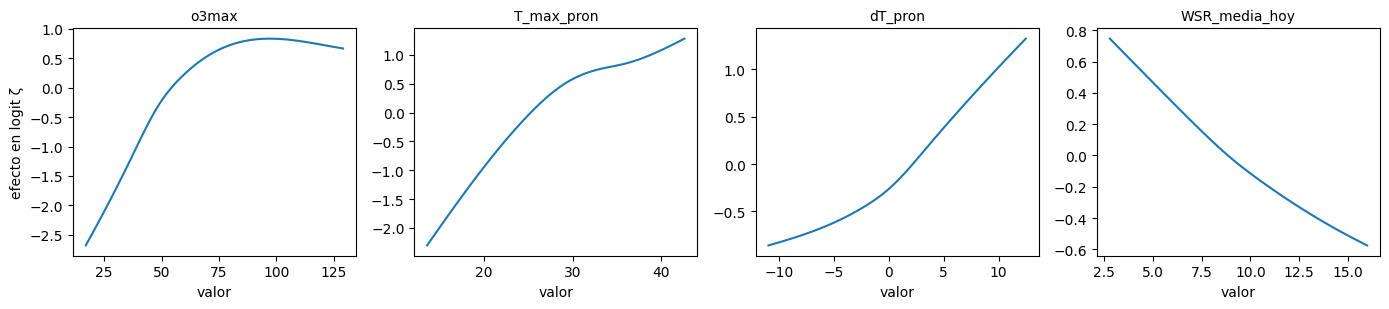

In [8]:
# Forma de las curvas del GAM: efecto de cada variable en el logit de ζ (las demás fijas)
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.2))
for eje, v in zip(ejes, ["o3max", "T_max_pron", "dT_pron", "WSR_media_hoy"]):
    i = CONT_D.index(v)
    malla = np.linspace(ent_d[v].quantile(0.01), ent_d[v].quantile(0.99), 100)
    base = np.tile(ent_d[CONT_D].median().to_numpy(), (100, 1))
    base[:, i] = malla
    fila = pd.DataFrame(np.tile(ent_d[LIN_GAM].mean().to_numpy(), (100, 1)), columns=LIN_GAM)
    lp = m_gam.predict(exog=sm.add_constant(fila, has_constant="add"), exog_smooth=base, which="linear")
    eje.plot(malla, lp - np.mean(lp))
    eje.set_title(v, fontsize=10)
    eje.set_xlabel("valor")
ejes[0].set_ylabel("efecto en logit ζ")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_gam_curvas.png", dpi=200)
plt.show()

**Lectura de las curvas** (efecto en logit $\zeta$ con las demás variables fijas):
- **Ozono de hoy:** el efecto crece rápido hasta ~75 ppb y luego se aplana: la curvatura que la recta no captaba.
- **Temperatura máxima pronosticada:** a más calor, más riesgo; crece más lento arriba de 30 °C.
- **Cambio de temperatura (`dT_pron`):** si mañana será más caliente que hoy, el riesgo sube, más allá del nivel.
- **Viento de hoy:** baja el riesgo (dispersa el ozono).

Grupos (de 10) con residual promedio fuera de ±2 EE, entrenamiento:
modelo         GAM penalizado  lineal  splines de regresión
variable                                                   
RH_media_hoy                0       1                     0
SR_max_hoy                  0       0                     0
T_max_pron                  0       2                     0
WSR_media_hoy               0       0                     0
dT_pron                     0       0                     0
horas63                     0       0                     0
horas63_7d                  0       1                     0
o3max                       0       2                     0
o3max_ciudad                0       1                     0
o3media                     0       0                     0
rango_pron                  0       0                     0
Total: {'GAM penalizado': 0, 'lineal': 7, 'splines de regresión': 0} | esperado solo por azar ≈ 5.1


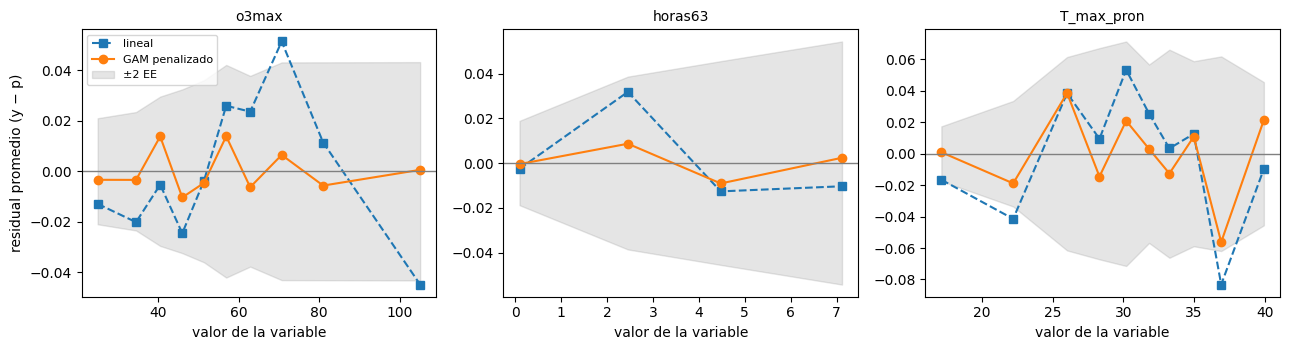

In [9]:
# --- 3.3 Diagnóstico de linealidad: residuales agrupados (Gelman y Hill, 2007) ---
# Para cada variable: 10 grupos por deciles; en cada grupo, residual promedio (y - p).
# Si el modelo está bien especificado, los promedios caen dentro de ±2 errores estándar.
# El error estándar se agrupa por FECHA: las 15 estaciones del mismo día no son independientes.
def residuales_agrupados(datos, p, v, y="y63", grupos=10):
    t = pd.DataFrame({"x": datos[v].to_numpy(), "r": datos[y].to_numpy() - p,
                      "fecha": datos["fecha"].to_numpy()})
    t["g"] = pd.qcut(t["x"], grupos, duplicates="drop")
    filas = []
    for _, q in t.groupby("g", observed=True):
        suma_dia = q.groupby("fecha")["r"].sum()
        filas.append({"x": q["x"].mean(), "r": q["r"].mean(), "n": len(q),
                      "ee": np.sqrt((suma_dia ** 2).sum()) / len(q)})
    return pd.DataFrame(filas)


p_lin = predecir_d(m_lin, ent_d)
p_adi = predecir_d(m_adi, ent_d)
p_gam = predecir_gam(m_gam, ent_d)
filas = []
for v in CONT_D:
    for nombre, p in [("lineal", p_lin), ("splines de regresión", p_adi), ("GAM penalizado", p_gam)]:
        g = residuales_agrupados(ent_d, p, v)
        filas.append({"variable": v, "modelo": nombre,
                      "grupos fuera de ±2 EE": int((g["r"].abs() > 2 * g["ee"]).sum()),
                      "de": len(g)})
diag_lin = pd.DataFrame(filas).pivot(index="variable", columns="modelo", values="grupos fuera de ±2 EE")
print("Grupos (de 10) con residual promedio fuera de ±2 EE, entrenamiento:")
print(diag_lin)
print("Total:", diag_lin.sum().to_dict(), "| esperado solo por azar ≈", round(diag_lin.shape[0] * 10 * 0.046, 1))

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
for eje, v in zip(ejes, ["o3max", "horas63", "T_max_pron"]):
    for nombre, p, marca in [("lineal", p_lin, "s--"), ("GAM penalizado", p_gam, "o-")]:
        g = residuales_agrupados(ent_d, p, v)
        eje.plot(g["x"], g["r"], marca, label=nombre)
    g = residuales_agrupados(ent_d, p_gam, v)
    eje.fill_between(g["x"], -2 * g["ee"], 2 * g["ee"], color="gray", alpha=0.2, label="±2 EE")
    eje.axhline(0, color="gray", lw=1)
    eje.set_title(v, fontsize=10)
    eje.set_xlabel("valor de la variable")
ejes[0].set_ylabel("residual promedio (y − p)")
ejes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_residuales_agrupados.png", dpi=200)
plt.show()

**Lectura.** En el modelo lineal, 7 de los 110 grupos tienen un residual promedio fuera de ±2 errores
estándar (por azar se esperarían ~5); en los dos GAM, **0 de 110**. La evidencia formal de la no linealidad
es la prueba de Wald de arriba; este diagnóstico muestra que el GAM ya no deja patrón en los residuales.

In [10]:
# --- 3.3b Predictores relacionados: correlación, VIF y concurvidad ---
# Concurvidad (la versión GAM de la multicolinealidad): qué tanto de la curva de una variable se puede
# reproducir con las curvas de las demás (R² entre 0 y 1; cerca de 1 = no se pueden separar).
from statsmodels.stats.outliers_influence import variance_inflation_factor


def concurvidad(datos, cont):
    bases = {v: BSplines(datos[[v]].to_numpy(), df=[6], degree=[3], include_intercept=False).basis
             for v in cont}
    resultado = {}
    for v in cont:
        Y = bases[v]
        X = np.column_stack([np.ones(len(datos))] + [bases[w] for w in cont if w != v])
        beta = np.linalg.lstsq(X, Y, rcond=None)[0]
        resto = Y - X @ beta
        resultado[v] = 1 - (resto ** 2).sum() / ((Y - Y.mean(0)) ** 2).sum()
    return resultado


def vif(datos, cont):
    X = datos[cont].assign(constante=1.0).to_numpy()
    return {v: variance_inflation_factor(X, i) for i, v in enumerate(cont)}


CLIMA_ORIGINAL = ["T_max_hoy", "SR_max_hoy", "RH_media_hoy", "WSR_media_hoy", "T_max_pron", "T_min_pron"]
OZONO_D = ["o3max", "o3media", "horas63", "horas63_7d", "o3max_ciudad"]
print("Correlación entre las temperaturas originales:")
print(ent_d[["T_max_hoy", "T_max_pron", "T_min_pron"]].corr().round(2))
print("\nCorrelación con la temperatura reexpresada:")
print(ent_d[["T_max_pron", "dT_pron", "rango_pron"]].corr().round(2))

filas = []
for nombre, cont in [("clima original", OZONO_D + CLIMA_ORIGINAL), ("clima reexpresado (final)", CONT_D)]:
    vi, cc = vif(ent_d, cont), concurvidad(ent_d, cont)
    for v in cont:
        filas.append({"versión": nombre, "variable": v, "VIF": vi[v], "concurvidad": cc[v]})
colin = pd.DataFrame(filas)
colin.pivot(index="variable", columns="versión", values=["VIF", "concurvidad"]).round(2)

Correlación entre las temperaturas originales:
            T_max_hoy  T_max_pron  T_min_pron
T_max_hoy        1.00        0.79        0.82
T_max_pron       0.79        1.00        0.84
T_min_pron       0.82        0.84        1.00

Correlación con la temperatura reexpresada:
            T_max_pron  dT_pron  rango_pron
T_max_pron        1.00     0.33        0.69
dT_pron           0.33     1.00        0.54
rango_pron        0.69     0.54        1.00


VIF                              concurvidad  \
versión       clima original clima reexpresado (final) clima original   
variable                                                                
RH_media_hoy            1.93                      1.93           0.46   
SR_max_hoy              1.39                      1.39           0.32   
T_max_hoy               5.63                       NaN           0.71   
T_max_pron              4.53                      2.64           0.66   
T_min_pron              6.40                       NaN           0.73   
WSR_media_hoy           1.19                      1.19           0.24   
dT_pron                  NaN                      2.34            NaN   
horas63                 3.69                      3.69           0.78   
horas63_7d              1.99                      1.99           0.21   
o3max                   6.40                      6.40           0.83   
o3max_ciudad            4.73                      4.73           0.71   
o3media                 3.16                      3.16           0.63   
rango_pron               NaN                      3.54            NaN   

                                         
versión       clima reexpresado (final)  
variable                                 
RH_media_hoy                       0.43  
SR_max_hoy                         0.31  
T_max_hoy                           NaN  
T_max_pron                         0.54  
T_min_pron                          NaN  
WSR_media_hoy                      0.23  
dT_pron                            0.40  
horas63                            0.78  
horas63_7d                         0.21  
o3max                              0.83  
o3max_ciudad                       0.70  
o3media                            0.63  
rango_pron                         0.50

**Lectura (predictores relacionados).** Las tres temperaturas originales tienen correlaciones de 0.79–0.84
(VIF hasta 6.4, concurvidad hasta 0.73): sería difícil separar sus curvas. Reexpresadas como **nivel**
(`T_max_pron`), **cambio** (`dT_pron` = mañana − hoy) y **rango** (`rango_pron` = máxima − mínima), contienen la
misma información pero el VIF máximo del clima baja a 2.6 y la concurvidad a 0.54. Como comprobación, al
final se ajusta también el GAM con el clima resumido por **ACP** (componentes no correlacionadas por
construcción) y da el mismo resultado en 2026.

Las variables de ozono (`o3max`, `horas63`, `o3max_ciudad`) siguen relacionadas entre sí (concurvidad
0.70–0.83): sus curvas se interpretan **como bloque** ("persistencia del episodio"), no una por una. Esto no
afecta la predicción, solo la interpretación individual.

              rezago 1               rezago 2               rezago 7         \
                  mean    min    max     mean    min    max     mean    min   
periodo                                                                       
entrenamiento   -0.015 -0.092  0.099    0.053 -0.005  0.091   -0.033 -0.089   
prueba          -0.034 -0.172  0.036   -0.027 -0.123  0.046    0.043 -0.047   
validación      -0.061 -0.142  0.023    0.084 -0.011  0.229    0.017 -0.068   

                     Ljung-Box p<0.05  
                 max                   
periodo                                
entrenamiento  0.054          2 de 15  
prueba         0.126          0 de 15  
validación     0.124          5 de 15  

Correlación promedio de residuales entre estaciones el mismo día: 0.358


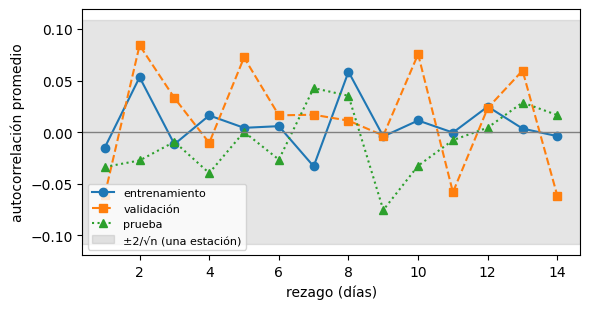

In [11]:
# --- 3.3c Autocorrelación de los residuales (entrenamiento, validación y prueba) ---
# Residual de Pearson del GAM para cada estación-día; se revisa por estación en el tiempo
# (rezagos de 1, 2 y 7 días + prueba de Ljung-Box) y entre estaciones el mismo día.
from statsmodels.stats.diagnostic import acorr_ljungbox

z_todo = np.clip(predecir_gam(m_gam, DIA), 1e-6, 1 - 1e-6)
DIA["resid_gam"] = (DIA["y63"] - z_todo) / np.sqrt(z_todo * (1 - z_todo))

filas = []
for per in ["entrenamiento", "validación", "prueba"]:
    for st, q in DIA[DIA["periodo"] == per].groupby("estacion"):
        r = q.set_index("fecha")["resid_gam"].asfreq("D")      # días faltantes quedan como NaN
        filas.append({"periodo": per, "estación": st,
                      "rezago 1": r.autocorr(1), "rezago 2": r.autocorr(2), "rezago 7": r.autocorr(7),
                      "Ljung-Box p (7 días)": acorr_ljungbox(r.dropna(), lags=[7], return_df=True)["lb_pvalue"].iloc[0]})
autoc = pd.DataFrame(filas)
resumen_ac = autoc.groupby("periodo")[["rezago 1", "rezago 2", "rezago 7"]].agg(["mean", "min", "max"]).round(3)
resumen_ac["Ljung-Box p<0.05"] = autoc.groupby("periodo")["Ljung-Box p (7 días)"].apply(lambda p: f"{(p < 0.05).sum()} de 15")
print(resumen_ac)

# Entre estaciones el mismo día (dependencia espacial)
matriz = DIA[DIA["periodo"] == "entrenamiento"].pivot_table(index="fecha", columns="estacion", values="resid_gam")
cm = matriz.corr().to_numpy()
print("\nCorrelación promedio de residuales entre estaciones el mismo día:",
      round(np.nanmean(cm[np.triu_indices_from(cm, 1)]), 3))

# Función de autocorrelación promedio de las 15 estaciones
fig, eje = plt.subplots(figsize=(6, 3.2))
for per, marca in [("entrenamiento", "o-"), ("validación", "s--"), ("prueba", "^:")]:
    acf = []
    for k in range(1, 15):
        acf.append(np.mean([q.set_index("fecha")["resid_gam"].asfreq("D").autocorr(k)
                            for _, q in DIA[DIA["periodo"] == per].groupby("estacion")]))
    eje.plot(range(1, 15), acf, marca, label=per)
n_tipico = DIA[DIA["periodo"] == "validación"].groupby("estacion").size().median()
eje.axhspan(-2 / np.sqrt(n_tipico), 2 / np.sqrt(n_tipico), color="gray", alpha=0.2, label="±2/√n (una estación)")
eje.axhline(0, color="gray", lw=1)
eje.set_xlabel("rezago (días)")
eje.set_ylabel("autocorrelación promedio")
eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_gam_autocorrelacion.png", dpi=200)
plt.show()

**Lectura (autocorrelación).**
- **En el tiempo:** la autocorrelación de los residuales es pequeña en los tres periodos (promedio entre
  −0.06 y 0.08; todos los rezagos dentro de la banda ±2/√n de la figura). Ljung-Box (7 días) la detecta en
  2 de 15 estaciones en entrenamiento, 5 de 15 en validación y 0 de 15 en prueba, siempre con valores
  bajos (|r| < 0.23). Las variables de persistencia (ozono de hoy, horas arriba de 63 en la semana)
  absorben casi toda la dependencia día a día.
- **Entre estaciones el mismo día:** los residuales sí están correlacionados (0.36 en promedio): un día con
  más ozono del esperado lo es en toda la ciudad (coherente con la Parte 2). Por eso los errores estándar
  se agrupan por fecha y la penalización se elige con validación en vez de GCV.
- La autocorrelación no sesga las probabilidades (se evalúan fuera de muestra); solo afectaría la
  precisión de los errores estándar, que ya son robustos.

                  coef      ee         z    p  exp(coef)
intercepto      3.0413  0.0201  151.1414  0.0    20.9330
logit_zeta_gam  0.3684  0.0143   25.7134  0.0     1.4454
xi             -0.1660  0.0102  -16.2732  0.0        NaN
¿logit(zeta) ayuda a sigma? D = 749.1, gl = 1, p = 6.2e-165
¿log(sigma) es lineal en logit(zeta)? D = 48.5, gl = 2, p = 2.9e-11
AIC GPD lineal: 25056.3 | con spline: 25011.7


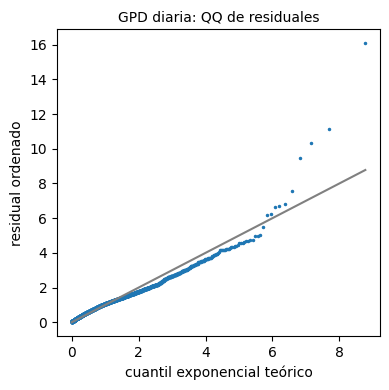

In [12]:
# --- 3.4 Segunda parte: GPD del exceso del máximo diario, sigma depende de logit(zeta) ---
DIA["zeta_lin"] = predecir_d(m_lin, DIA)
DIA["zeta_adi"] = predecir_d(m_adi, DIA)
DIA["zeta_gam"] = np.clip(predecir_gam(m_gam, DIA), 1e-6, 1 - 1e-6)
for z in ["zeta_lin", "zeta_adi", "zeta_gam"]:
    DIA["logit_" + z] = np.log(DIA[z] / (1 - DIA[z]))
ent_d = DIA[DIA["periodo"] == "entrenamiento"]
exc_d = ent_d[ent_d["y63"] == 1].copy()
exc_d["y"] = exc_d["max_manana"] - U
g0 = ajustar_gpd(exc_d, [])


def gpd_con_spline(z):
    # log(sigma) = b0 + b1·logit(zeta) + spline de logit(zeta): sin suponer linealidad
    col = "logit_" + z
    nud = np.quantile(exc_d[col], [0.05, 0.35, 0.65, 0.95])
    nombres = []
    for tabla in [exc_d, DIA]:
        B = spline_restringido(tabla[col], nud)
        for j in range(B.shape[1]):
            tabla[f"{z}_lz{j + 1}"] = B[:, j]
    nombres = [f"{z}_lz{j + 1}" for j in range(B.shape[1])]
    recta = ajustar_gpd(exc_d, [col], inicio=g0)
    curva = ajustar_gpd(exc_d, [col] + nombres, inicio=recta)
    return recta, curva


g_lin, _ = gpd_con_spline("zeta_lin")              # modelo lineal: todo lineal
_, g_adi = gpd_con_spline("zeta_adi")
g_recta, g_gam = gpd_con_spline("zeta_gam")
print(resumen_gpd(g_recta).round(4))
D, gl, p = prueba_rv(g0, g_recta)
print(f"¿logit(zeta) ayuda a sigma? D = {D:.1f}, gl = {gl}, p = {p:.2g}")
D, gl, p = prueba_rv(g_recta, g_gam)
print(f"¿log(sigma) es lineal en logit(zeta)? D = {D:.1f}, gl = {gl}, p = {p:.2g}")
print(f"AIC GPD lineal: {aic(g_recta):.1f} | con spline: {aic(g_gam):.1f}")

# Residuales exponenciales de la GPD (deben seguir una exponencial(1))
r = np.sort(residuales_gpd(g_gam))
teo = -np.log(1 - (np.arange(1, len(r) + 1) - 0.5) / len(r))
plt.figure(figsize=(4, 4))
plt.plot(teo, r, ".", ms=3)
plt.plot([0, teo.max()], [0, teo.max()], color="gray")
plt.xlabel("cuantil exponencial teórico")
plt.ylabel("residual ordenado")
plt.title("GPD diaria: QQ de residuales", fontsize=10)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "final_qq_diaria.png", dpi=200)
plt.show()

**Lectura.** $\zeta$ también decide qué tan grande es el exceso: si logit $\zeta$ sube 1, la escala $\sigma$
se multiplica por ~1.45 ($p \approx 10^{-165}$). La relación tampoco es lineal ($D = 48.5$, $p < 0.001$), así
que $\sigma$ también entra con un spline: **ninguna de las dos partes supone linealidad**. $\xi \approx -0.17$
indica una cola con máximo. El QQ de residuales sigue la exponencial, con algunos valores altos arriba de
la línea (los picos más extremos son algo más grandes de lo que el modelo espera).

In [13]:
# --- 3.5 Evaluación fuera de muestra (2025 elige, 2026 reporta) ---
from sklearn.ensemble import HistGradientBoostingClassifier


def prob_dos_partes(g, col_zeta, datos, nivel):
    return datos[col_zeta].to_numpy() * prob_mayor_gpd(nivel - U, sigma_gpd(g, datos), g["params"][-1])


# Referencia sin ningún supuesto de forma: gradient boosting directo para P(max > 90)
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                    min_samples_leaf=40, l2_regularization=1.0, random_state=0)
gb.fit(ent_d[LINEAL_D], ent_d["y90"])

DIA["p90_lineal"] = prob_dos_partes(g_lin, "zeta_lin", DIA, C)
DIA["p90_aditivo"] = prob_dos_partes(g_adi, "zeta_adi", DIA, C)
DIA["p90_gam"] = prob_dos_partes(g_gam, "zeta_gam", DIA, C)
DIA["p90_boosting"] = gb.predict_proba(DIA[LINEAL_D])[:, 1]

# Alternativa: clima resumido con ACP (componentes no correlacionadas por construcción)
media_c, desv_c = ent_d[CLIMA_ORIGINAL].mean(), ent_d[CLIMA_ORIGINAL].std()
valores_c, vectores_c = np.linalg.eigh(np.cov(((ent_d[CLIMA_ORIGINAL] - media_c) / desv_c).to_numpy().T))
orden = np.argsort(valores_c)[::-1]
vectores_c = vectores_c[:, orden]
CP_CLIMA = [f"CPclima{k + 1}" for k in range(len(CLIMA_ORIGINAL))]
DIA[CP_CLIMA] = ((DIA[CLIMA_ORIGINAL] - media_c) / desv_c).to_numpy() @ vectores_c
ent_d = DIA[DIA["periodo"] == "entrenamiento"]
m_acp = ajustar_gam(ent_d, ALPHA, OZONO_D + CP_CLIMA)
DIA["zeta_acp"] = np.clip(predecir_gam(m_acp, DIA), 1e-6, 1 - 1e-6)
DIA["logit_zeta_acp"] = np.log(DIA["zeta_acp"] / (1 - DIA["zeta_acp"]))
exc_d = DIA[(DIA["periodo"] == "entrenamiento") & (DIA["y63"] == 1)].copy()
exc_d["y"] = exc_d["max_manana"] - U
_, g_acp = gpd_con_spline("zeta_acp")
DIA["p90_acp"] = prob_dos_partes(g_acp, "zeta_acp", DIA, C)
clima_d = ent_d.groupby("estacion")["y90"].mean()
DIA["p90_clima"] = DIA["estacion"].map(clima_d)
clima63 = ent_d.groupby("estacion")["y63"].mean()
DIA["p63_clima"] = DIA["estacion"].map(clima63)

MODELOS_D = {"climatología": "p90_clima", "dos partes, lineal": "p90_lineal",
             "dos partes, splines de regresión": "p90_aditivo", "dos partes, GAM penalizado": "p90_gam",
             "dos partes, GAM con clima en ACP": "p90_acp",
             "boosting (sin supuestos)": "p90_boosting"}
ZETA_D = {"dos partes, lineal": "zeta_lin", "dos partes, splines de regresión": "zeta_adi",
          "dos partes, GAM penalizado": "zeta_gam", "dos partes, GAM con clima en ACP": "zeta_acp"}
filas = []
cortes_d = {}
for nombre, col in MODELOS_D.items():
    v25 = DIA[DIA["periodo"] == "validación"]
    for tau in np.sort(v25[col].unique())[::-1]:          # corte para detectar 70 % de los días en 2025
        if alertas(v25["y90"], v25[col], tau)["aciertos"] >= 0.7:
            break
    cortes_d[nombre] = tau
    for per, etiqueta in [("validación", "2025"), ("prueba", "2026")]:
        t = DIA[DIA["periodo"] == per]
        a = alertas(t["y90"], t[col], tau)
        fila = {"modelo": nombre, "año": etiqueta, **metricas(t["y90"], t[col], t["p90_clima"]),
                "aciertos": a["aciertos"], "falsas alarmas": a["razón falsas alarmas"]}
        if nombre in ZETA_D:
            fila["BSS ζ"] = metricas(t["y63"], t[ZETA_D[nombre]], t["p63_clima"])["bss"]
        filas.append(fila)
tabla_d = pd.DataFrame(filas).set_index(["año", "modelo"])
tabla_d[["n", "eventos", "auc", "bss", "BSS ζ", "aciertos", "falsas alarmas"]].round(3)

,,n,eventos,auc,bss,BSS ζ,aciertos,falsas alarmas
año,modelo,,,,,,,
2025,climatología,4960,609,0.668,0.000,NaN,0.701,0.814
2026,climatología,3045,344,0.641,0.000,NaN,0.672,0.836
2025,"dos partes, lineal",4960,609,0.855,0.194,0.332,0.701,0.645
2026,"dos partes, lineal",3045,344,0.887,0.254,0.336,0.741,0.620
2025,"dos partes, splines de regresión",4960,609,0.857,0.208,0.349,0.701,0.616
2026,"dos partes, splines de regresión",3045,344,0.884,0.254,0.340,0.709,0.603
2025,"dos partes, GAM penalizado",4960,609,0.859,0.210,0.351,0.701,0.633
2026,"dos partes, GAM penalizado",3045,344,0.885,0.261,0.342,0.715,0.613
2025,"dos partes, GAM con clima en ACP",4960,609,0.856,0.200,0.347,0.701,0.631


**Lectura.**
- El **GAM penalizado** es el mejor en **validación 2025** (BSS de $P(>90)$ 0.210, contra 0.208 de los splines
  de regresión, 0.200 del GAM con ACP, 0.194 del lineal y 0.185 del boosting), así que es el elegido. En
  2026: BSS 0.261, AUC 0.885, detecta 72 % de los días con 61 % de falsas alarmas.
- El GAM con el clima en **ACP** da lo mismo en 2026 (0.261): el resultado no depende de cómo se manejen
  las variables climáticas correlacionadas.
- Comparado con el modelo horario de la Parte 1C, mejora mucho como alerta diaria: AUC por día 0.89
  (antes 0.81), falsas alarmas 61 % (antes 71 %).
- El **boosting**, que no supone ninguna forma, no supera al GAM: el límite no es la forma del modelo
  sino la información disponible.

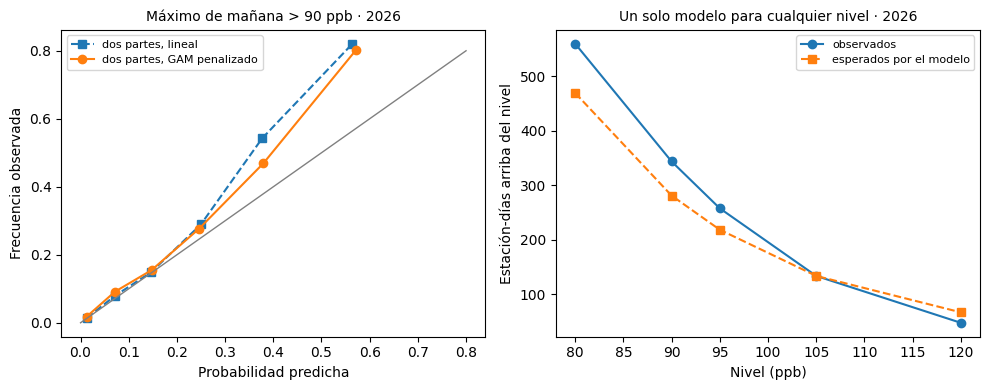

,días observados,días esperados,AUC
nivel,,,
80,560,469.550,0.884
90,344,281.371,0.885
95,258,218.707,0.892
105,134,134.037,0.905
120,48,67.215,0.895


In [14]:
# --- 3.6 Calibración 2026 y probabilidad de superar otros niveles (ventaja de la GPD) ---
prueba_d = DIA[DIA["periodo"] == "prueba"]
cortes = [0, .05, .1, .2, .3, .5, 1]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for nombre, marca in [("dos partes, lineal", "s--"), ("dos partes, GAM penalizado", "o-")]:
    cal = calibracion(prueba_d["y90"], prueba_d[MODELOS_D[nombre]], cortes)
    ejes[0].plot(cal["pred"], cal["obs"], marca, label=nombre)
ejes[0].plot([0, .8], [0, .8], color="gray", lw=1)
ejes[0].set_xlabel("Probabilidad predicha")
ejes[0].set_ylabel("Frecuencia observada")
ejes[0].set_title(f"Máximo de mañana > {C:.0f} ppb · 2026", fontsize=10)
ejes[0].legend(fontsize=8)

filas = []
for nivel in [80, 90, 95, 105, 120]:
    y = (prueba_d["max_manana"] > nivel).astype(float)
    p = prob_dos_partes(g_gam, "zeta_gam", prueba_d, nivel)
    filas.append({"nivel": nivel, "días observados": int(y.sum()), "días esperados": p.sum(),
                  "AUC": roc_auc_score(y, p) if y.sum() > 0 else np.nan})
niveles = pd.DataFrame(filas).set_index("nivel")
ejes[1].plot(niveles.index, niveles["días observados"], "o-", label="observados")
ejes[1].plot(niveles.index, niveles["días esperados"], "s--", label="esperados por el modelo")
ejes[1].set_xlabel("Nivel (ppb)")
ejes[1].set_ylabel("Estación-días arriba del nivel")
ejes[1].set_title("Un solo modelo para cualquier nivel · 2026", fontsize=10)
ejes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS + "final_diario_calibracion_niveles.png", dpi=200)
plt.show()
niveles.round(3)

**Lectura.**
- **Calibración:** el GAM queda más cerca de la diagonal que el lineal en las probabilidades altas, aunque
  todavía subestima un poco arriba de 30 %: 2026 tuvo más ozono que los años de entrenamiento.
- **Ventaja de la GPD:** con el mismo modelo se obtiene la probabilidad de superar cualquier nivel. Para
  105 ppb esperaba 134 estación-días y hubo 134; para 120 ppb, 67 contra 48. Una logística directa
  necesitaría un modelo nuevo por cada nivel.

**Conclusión de la Parte 3.** El modelo propuesto (GAM binario + GPD) no supone linealidad (Wald y residuales
agrupados), separa mejor las variables climáticas (VIF máximo 2.6), deja residuales casi sin
autocorrelación en el tiempo, conserva la estructura de dos partes de Gyarmati-Szabó et al. (2016) y,
como alerta diaria, supera al modelo horario (AUC 0.81 → 0.89; falsas alarmas 71 % → 61 %). Un modelo sin
supuestos (gradient boosting) no lo supera.